<a href="https://colab.research.google.com/github/BhuvanHande/ML-Lab/blob/main/Breast_cancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

path = kagglehub.dataset_download("mariolisboa/breast-cancer-wisconsin-original-data-set")

print("Path to dataset files:", path)

100%|██████████| 5.93k/5.93k [00:00<00:00, 9.16MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mariolisboa/breast-cancer-wisconsin-original-data-set/versions/1


In [ ]:
import os
import pandas as pd
from matplotlib import pyplot as plt

print(os.listdir(path))

['breast_cancer_bd.csv']


In [ ]:

df = pd.read_csv(os.path.join(path, "breast_cancer_bd.csv"))
print(df.describe())


       Sample code number  Clump Thickness  Uniformity of Cell Size  \
count        6.990000e+02       699.000000               699.000000   
mean         1.071704e+06         4.417740                 3.134478   
std          6.170957e+05         2.815741                 3.051459   
min          6.163400e+04         1.000000                 1.000000   
25%          8.706885e+05         2.000000                 1.000000   
50%          1.171710e+06         4.000000                 1.000000   
75%          1.238298e+06         6.000000                 5.000000   
max          1.345435e+07        10.000000                10.000000   

       Uniformity of Cell Shape  Marginal Adhesion  \
count                699.000000         699.000000   
mean                   3.207439           2.806867   
std                    2.971913           2.855379   
min                    1.000000           1.000000   
25%                    1.000000           1.000000   
50%                    1.000000     

In [ ]:
print(df.head(10))


   Sample code number  Clump Thickness  Uniformity of Cell Size  \
0             1000025                5                        1   
1             1002945                5                        4   
2             1015425                3                        1   
3             1016277                6                        8   
4             1017023                4                        1   
5             1017122                8                       10   
6             1018099                1                        1   
7             1018561                2                        1   
8             1033078                2                        1   
9             1033078                4                        2   

   Uniformity of Cell Shape  Marginal Adhesion  Single Epithelial Cell Size  \
0                         1                  1                            2   
1                         4                  5                            7   
2                        

In [ ]:
print(df.shape)
print("\ncolumn",df.columns.tolist())

(699, 11)

column ['Sample code number', 'Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin', 'Normal Nucleoli', 'Mitoses', 'Class']


In [ ]:
print("\nDataTypes", df.dtypes)


DataTypes Sample code number              int64
Clump Thickness                 int64
Uniformity of Cell Size         int64
Uniformity of Cell Shape        int64
Marginal Adhesion               int64
Single Epithelial Cell Size     int64
Bare Nuclei                    object
Bland Chromatin                 int64
Normal Nucleoli                 int64
Mitoses                         int64
Class                           int64
dtype: object


In [ ]:

print(df.isnull().sum())

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64


In [ ]:
missing = df.isnull().sum()
percentage = (missing / len(df)) * 100

print("\nMissing percentage:")
print(percentage)


Missing percentage:
Sample code number             0.0
Clump Thickness                0.0
Uniformity of Cell Size        0.0
Uniformity of Cell Shape       0.0
Marginal Adhesion              0.0
Single Epithelial Cell Size    0.0
Bare Nuclei                    0.0
Bland Chromatin                0.0
Normal Nucleoli                0.0
Mitoses                        0.0
Class                          0.0
dtype: float64


In [ ]:
# one hot encoding(since there is no data with non numerical datatype we dont need to use One-Hot Encoding)
print(df["Bare Nuclei"].unique())

['1' '10' '2' '4' '3' '9' '7' '?' '5' '8' '6']


In [ ]:
# since all the features are available in the dataset we need not make any extra feature extraction but we have to do the feature seection process

In [ ]:
# this is to replace the "?" with NaN and converting the datatype from object to float
df["Bare Nuclei"] = df["Bare Nuclei"].replace("?", np.nan)
df["Bare Nuclei"] = df["Bare Nuclei"].astype(float)

In [ ]:
print(df.isnull().sum())

Sample code number              0
Clump Thickness                 0
Uniformity of Cell Size         0
Uniformity of Cell Shape        0
Marginal Adhesion               0
Single Epithelial Cell Size     0
Bare Nuclei                    16
Bland Chromatin                 0
Normal Nucleoli                 0
Mitoses                         0
Class                           0
dtype: int64


In [ ]:
print(df.dtypes)


Sample code number               int64
Clump Thickness                  int64
Uniformity of Cell Size          int64
Uniformity of Cell Shape         int64
Marginal Adhesion                int64
Single Epithelial Cell Size      int64
Bare Nuclei                    float64
Bland Chromatin                  int64
Normal Nucleoli                  int64
Mitoses                          int64
Class                            int64
dtype: object


In [ ]:
df["Bare Nuclei"] = df["Bare Nuclei"].fillna(
    df["Bare Nuclei"].median()
)

In [ ]:
print(df.isnull().sum())

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df.drop(['Sample code number', 'Class'], axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

# Train the model using scaled training data
linear_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

# Train the model using unscaled training data
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
y_pred_linear = linear_model.predict(X_test_scaled)

In [ ]:
y_pred_tree = tree_model.predict(X_test)

In [ ]:
# Convert continuous predictions to classes
y_pred_linear_class = np.where(
    y_pred_linear < 3,
    2,
    4
)

Decision Tree
--------------------
Accuracy : 0.9357142857142857
Precision: 0.9285714285714286
Recall   : 0.8666666666666667
F1 Score : 0.896551724137931


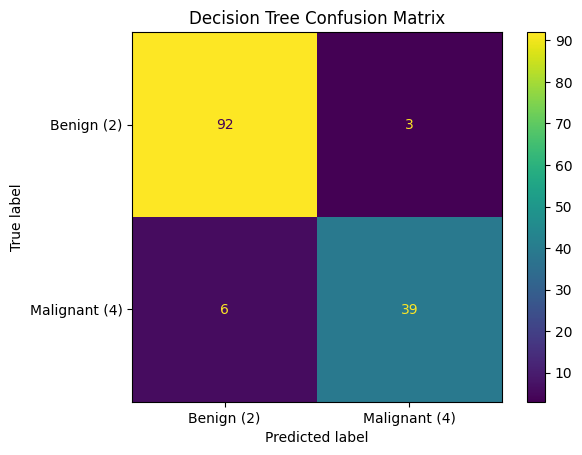

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Decision Tree predictions
y_pred_tree = tree_model.predict(X_test)

# Metrics
print("Decision Tree")
print("--------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree, pos_label=4))
print("Recall   :", recall_score(y_test, y_pred_tree, pos_label=4))
print("F1 Score :", f1_score(y_test, y_pred_tree, pos_label=4))

# Confusion Matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["Benign (2)", "Malignant (4)"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

Linear Regression
--------------------
Accuracy : 0.9571428571428572
Precision: 0.975609756097561
Recall   : 0.8888888888888888
F1 Score : 0.9302325581395349


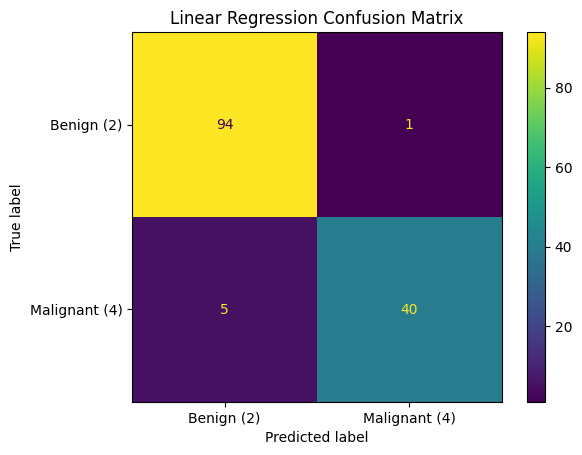

In [ ]:
print("Linear Regression")
print("--------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_linear_class))
print("Precision:", precision_score(y_test, y_pred_linear_class, pos_label=4))
print("Recall   :", recall_score(y_test, y_pred_linear_class, pos_label=4))
print("F1 Score :", f1_score(y_test, y_pred_linear_class, pos_label=4))

# Confusion Matrix
cm_linear = confusion_matrix(y_test, y_pred_linear_class)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=["Benign (2)", "Malignant (4)"]
)

disp.plot()
plt.title("Linear Regression Confusion Matrix")
plt.show()